# Alibaba PAI GPU trace 2020: a complete EDA (jobs, tasks, GPU types, heavy-tailed durations, queueing delay)

This notebook walks through the public Alibaba PAI GPU cluster trace from 2020: about two months of a production
machine learning cluster with 1,897 machines and 6,742 GPUs. You get the size and shape of every table, who submits
the work, what tasks ask for, how long they run, how long they wait for a machine and how often they fail, each
with the code to reproduce it.

- Data: the dataset [alibaba-gpu-trace-2020](https://www.kaggle.com/datasets/swapnilshukla007/alibaba-gpu-trace-2020), a CC BY 4.0 copy of [cluster-trace-gpu-v2020](https://github.com/alibaba/clusterdata/tree/master/cluster-trace-gpu-v2020) (Weng et al., NSDI 2022)
- Run time: about 1 minute on a Kaggle CPU notebook, no GPU needed
- Part 1 of a five-part series from the KANVAS project. Live app: [kanvas.streamlit.app](https://kanvas.streamlit.app) | Code: [github.com/Swapnil007-Curious/KANVAS](https://github.com/Swapnil007-Curious/KANVAS) | Paper: link to be added

## Contents

1. Setup and loading the tables
2. The cluster: machines and GPU types
3. Jobs, users and outcomes
4. Tasks and what they request
5. When work arrives
6. Heavy-tailed durations
7. Queueing delay
8. Failure rates at a glance
9. What we found, limitations and next steps

## 1. Setup and loading the tables

The trace has seven CSV tables. This notebook reads five of them; the sensor and machine-metric tables are the
subject of part 2. The instance table is 2 GB, so it is read with pyarrow, keeping only the columns we need and
storing the long hash strings as categories. That keeps it at about 0.3 GB in memory.

In [1]:
import os
import time
import warnings
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Paths. On Kaggle the defaults apply; the two environment variables let the same notebook run elsewhere.
INPUT_ROOT = Path(os.environ.get("KAGGLE_INPUT_ROOT", "/kaggle/input"))
WORKING = Path(os.environ.get("KAGGLE_WORKING", "/kaggle/working"))
WORKING.mkdir(parents=True, exist_ok=True)

# FAST = True runs a smaller version for a quick check on a small machine. Kaggle runs use the full data.
FAST = os.environ.get("KANVAS_FAST", "0") == "1"
SEED = 42  # one seed for every random choice in the notebook

# Okabe-Ito colours, chosen so the series stay distinct for the common forms of colour blindness.
BLUE, ORANGE, GREEN, VERMILLION, PURPLE, SKY, YELLOW, BLACK = (
    "#0072B2", "#E69F00", "#009E73", "#D55E00", "#CC79A7", "#56B4E9", "#F0E442", "#000000")
PALETTE = [BLUE, ORANGE, GREEN, VERMILLION, PURPLE, SKY, BLACK]
SEQUENTIAL_CMAP = "cividis"  # one perceptually uniform ramp for heatmaps

mpl.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 100, "font.size": 11, "axes.titlesize": 13, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3,
    "axes.prop_cycle": mpl.cycler(color=PALETTE), "legend.frameon": False,
})
np.random.seed(SEED)
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)


def find_data_dir(required, root=INPUT_ROOT, max_depth=4):
    """Return the first folder under ``root`` that contains every file in ``required``.

    Kaggle mounts attached datasets under /kaggle/input, and the exact sub-path has changed over the
    years, so the notebook searches for the files instead of hard-coding one layout.
    """
    root = Path(root)
    for dirpath, dirnames, filenames in os.walk(root):
        depth = len(Path(dirpath).relative_to(root).parts)
        if all(name in filenames for name in required):
            return Path(dirpath)
        if depth >= max_depth:
            dirnames[:] = []
    raise FileNotFoundError(
        f"Could not find {list(required)} under {root}. Attach the dataset 'alibaba-gpu-trace-2020' "
        "(Add Input > Datasets) and run again.")


def save_cover(draw, path=None):
    """Draw a 1280x720 cover image with ``draw(ax)`` and save it as cover.png in the working folder."""
    path = WORKING / "cover.png" if path is None else path
    fig, ax = plt.subplots(figsize=(12.8, 7.2), dpi=100)
    draw(ax)
    fig.tight_layout()
    fig.savefig(path, dpi=100)
    plt.close(fig)
    return path


print(f"pandas {pd.__version__}, numpy {np.__version__}, matplotlib {mpl.__version__}; FAST = {FAST}")

pandas 3.0.6, numpy 2.4.6, matplotlib 3.11.2; FAST = False


In [2]:
import pyarrow as pa
import pyarrow.csv as pacsv

DATA_DIR = find_data_dir(["pai_job_table.csv", "pai_task_table.csv", "pai_instance_table.csv"])
DAY = 86_400   # seconds per day; trace times are seconds with the real dates hidden by a constant shift
HOUR = 3_600
TOP_K = 10     # how many categories to show in the bar charts
LABELLED = ["Terminated", "Failed"]  # finished tasks; Running and Waiting had no outcome when the trace ended
RAMP_DAYS = 7  # the first week of the trace is nearly empty; arrival profiles start after it
GPU_ORDER = ["no GPU", "T4", "MISC", "P100", "V100", "V100M32"]  # plot order, roughly by queueing delay


def read_table(name, columns, float_cols=()):
    """Read selected columns of a trace CSV with pyarrow; string columns become pandas categories."""
    opts = pacsv.ConvertOptions(include_columns=list(columns), auto_dict_encode=True, strings_can_be_null=True,
                                auto_dict_max_cardinality=10**9,
                                column_types={c: pa.float64() for c in float_cols})
    return pacsv.read_csv(DATA_DIR / name, convert_options=opts).to_pandas()


t0 = time.perf_counter()
job = read_table("pai_job_table.csv", ["job_name", "inst_id", "user", "status", "start_time", "end_time"],
                 ["start_time", "end_time"])
task = read_table("pai_task_table.csv", ["job_name", "task_name", "inst_num", "status", "start_time", "end_time",
                                          "plan_cpu", "plan_mem", "plan_gpu", "gpu_type"],
                  ["start_time", "end_time", "plan_gpu", "inst_num"])
inst = read_table("pai_instance_table.csv", ["job_name", "task_name", "status", "start_time", "end_time", "machine"],
                  ["start_time", "end_time"])
spec = read_table("pai_machine_spec.csv", ["machine", "gpu_type", "cap_cpu", "cap_mem", "cap_gpu"])
tags = read_table("pai_group_tag_table.csv", ["inst_id", "gpu_type_spec", "workload"])
print(f"loaded in {time.perf_counter() - t0:.0f} s")

pd.DataFrame({name: {"rows": len(df), "columns": df.shape[1], "memory (MB)": round(df.memory_usage(deep=True).sum() / 1e6)}
              for name, df in [("job", job), ("task", task), ("instance", inst), ("machine spec", spec),
                               ("group tag", tags)]}).T

loaded in 7 s


,rows,columns,memory (MB)
job,1055501,6,202
task,1261050,10,137
instance,7522002,6,248
machine spec,1897,5,0
group tag,1055032,3,112


A job has one or more tasks (a parameter server and its workers, for example), and a task runs as one or more
instances, each on one machine. Trace time is in seconds; the real dates are hidden, but time of day is kept.

In [3]:
span_days = (job["start_time"].max() - job["start_time"].min()) / DAY
print(f"jobs: {len(job):,}   tasks: {len(task):,}   instances: {len(inst):,}")
print(f"users: {job['user'].nunique():,}   machines: {len(spec):,}   GPUs: {int(spec['cap_gpu'].sum()):,}")
print(f"job submissions span {span_days:.1f} days")
print(f"tasks per job: {task.groupby('job_name', observed=True).size().value_counts().sort_index().to_dict()}")

jobs: 1,055,501   tasks: 1,261,050   instances: 7,522,002
users: 1,433   machines: 1,897   GPUs: 6,742
job submissions span 68.9 days
tasks per job: {1: 867073, 2: 171447, 3: 16841, 4: 140}


## 2. The cluster: machines and GPU types

`pai_machine_spec` lists every machine with its GPU model and GPU count. MISC stands for older GPUs such as K40m,
K80 and M60.

CPU-only machines: 83


,machines,gpus,gpus_per_machine,share_of_gpus
gpu_type,,,,
MISC,280,2240,8.0,0.332246
P100,798,1596,2.0,0.236725
V100M32,135,1080,8.0,0.160190
T4,497,994,2.0,0.147434
V100,104,832,8.0,0.123406


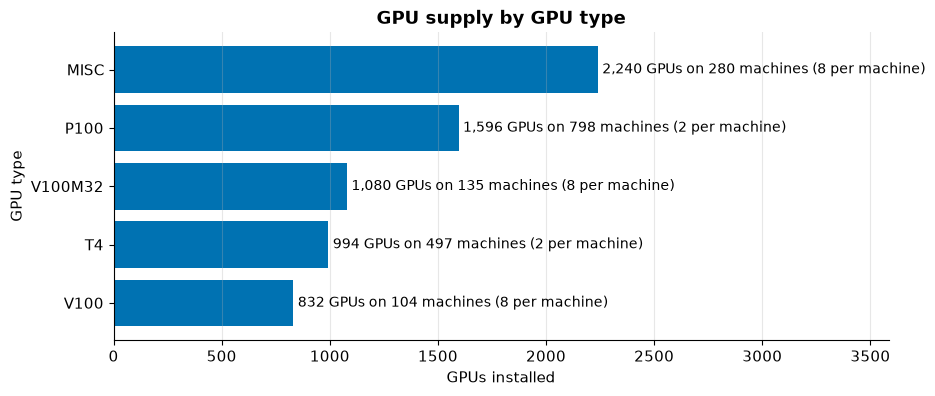

In [4]:
def gpu_supply(spec):
    """Machines and GPUs per GPU type, largest first."""
    out = (spec[spec["cap_gpu"] > 0].groupby("gpu_type", observed=True)
           .agg(machines=("machine", "size"), gpus=("cap_gpu", "sum"), gpus_per_machine=("cap_gpu", "median")))
    out["share_of_gpus"] = out["gpus"] / out["gpus"].sum()
    return out.sort_values("gpus", ascending=False)


def plot_gpu_supply(ax, supply):
    """Horizontal bars of GPU count per type, labelled with machine count and GPUs per machine."""
    s = supply.iloc[::-1]
    ax.barh(s.index.astype(str), s["gpus"], color=BLUE)
    for i, (gpus, m, g) in enumerate(zip(s["gpus"], s["machines"], s["gpus_per_machine"])):
        ax.text(gpus + 20, i, f"{gpus:,} GPUs on {m:,} machines ({g:.0f} per machine)", va="center", fontsize=10)
    ax.set_xlim(0, s["gpus"].max() * 1.6)
    ax.set_title("GPU supply by GPU type")
    ax.set_xlabel("GPUs installed")
    ax.set_ylabel("GPU type")
    ax.grid(axis="y", visible=False)


supply = gpu_supply(spec)
print(f"CPU-only machines: {int((spec['cap_gpu'] == 0).sum())}")
display(supply)
fig, ax = plt.subplots(figsize=(10, 4))
plot_gpu_supply(ax, supply)
plt.show()

Takeaway: a third of the GPUs (2,240 of 6,742) are older MISC cards in 8-GPU machines, and every P100 and T4
machine holds 2 GPUs, which matters for jobs that need many GPUs on one machine.

## 3. Jobs, users and outcomes

job status (%):


status,Terminated,Failed,Running,Waiting
percent,69.4,24.3,6.0,0.3


task status (%):


status,Terminated,Failed,Running,Waiting
percent,70.2,20.4,9.2,0.3


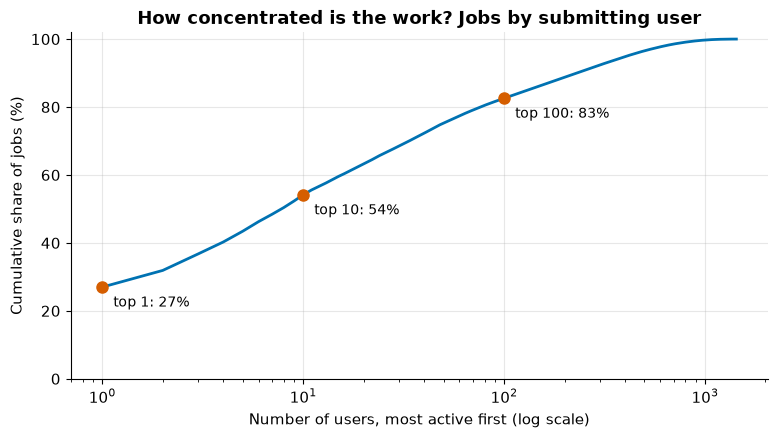

In [5]:
def status_shares(df):
    """Share of rows per status, as a one-row table in percent."""
    return (df["status"].value_counts(normalize=True) * 100).round(1).rename("percent").to_frame().T


def user_concentration(job):
    """Cumulative share of jobs held by the top-k users, for every k."""
    counts = job["user"].value_counts().to_numpy()
    return np.arange(1, len(counts) + 1), np.cumsum(counts) / counts.sum()


def plot_user_concentration(ax, k, share):
    """Cumulative share of jobs against the number of top users, log x-axis."""
    ax.plot(k, share * 100, color=BLUE, lw=2)
    for top in (1, 10, 100):
        ax.plot(top, share[top - 1] * 100, "o", color=VERMILLION, ms=8)
        ax.annotate(f"top {top}: {share[top - 1]:.0%}", (top, share[top - 1] * 100), xytext=(8, -14),
                    textcoords="offset points", fontsize=10)
    ax.set_xscale("log")
    ax.set_ylim(0, 102)
    ax.set_title("How concentrated is the work? Jobs by submitting user")
    ax.set_xlabel("Number of users, most active first (log scale)")
    ax.set_ylabel("Cumulative share of jobs (%)")


print("job status (%):")
display(status_shares(job))
print("task status (%):")
display(status_shares(task))
k, share = user_concentration(job)
fig, ax = plt.subplots(figsize=(9, 4.5))
plot_user_concentration(ax, k, share)
plt.show()

Takeaway: one user submits 27% of all jobs and the top 10 users submit about half, so any per-job statistic
(and any model trained on the jobs) is weighted heavily toward a handful of users.

## 4. Tasks and what they request

Each task row says what one instance asks for: `plan_cpu` (600 = 6 cores), `plan_mem` (GB), `plan_gpu`
(100 = one whole GPU, 25 = a quarter) and `inst_num`, the number of instances.

tasks with a GPU request: 1,037,085 (82.2%)
GPU tasks asking for less than one GPU per instance: 54.4%
tasks with a single instance: 76.4%; largest inst_num: 1,200


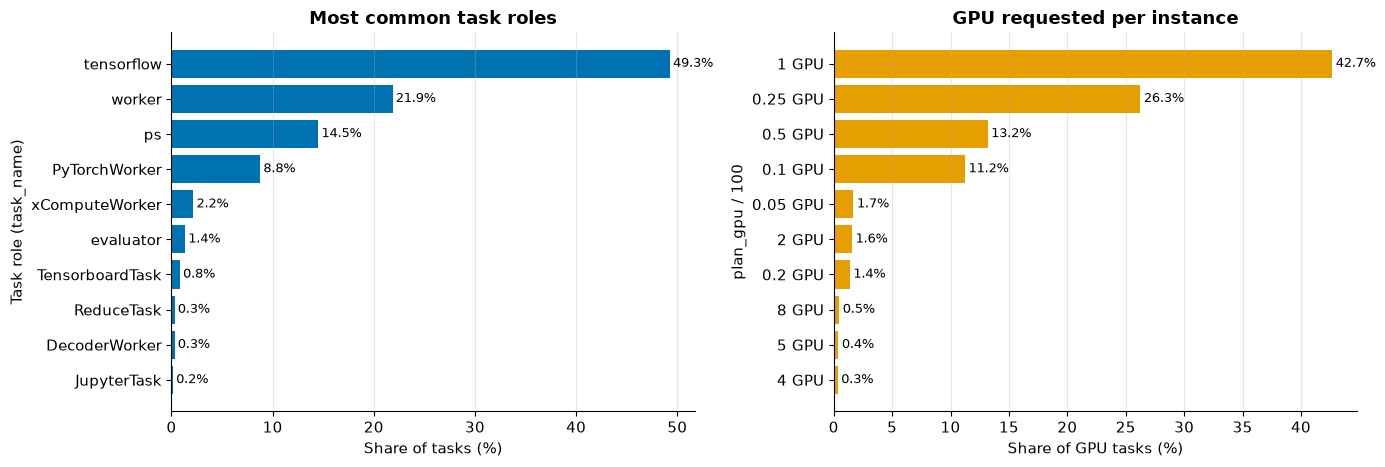

In [6]:
def plot_top_counts(ax, series, title, xlabel, color=BLUE, k=TOP_K):
    """Horizontal bars for the k most frequent values of a categorical series, as percent of rows."""
    vc = series.astype(str).value_counts(normalize=True).head(k).iloc[::-1] * 100
    ax.barh(vc.index, vc.values, color=color)
    for i, v in enumerate(vc.values):
        ax.text(v + 0.3, i, f"{v:.1f}%", va="center", fontsize=9)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.grid(axis="y", visible=False)


gpu_tasks = task[task["plan_gpu"].notna()]
print(f"tasks with a GPU request: {len(gpu_tasks):,} ({len(gpu_tasks) / len(task):.1%})")
print(f"GPU tasks asking for less than one GPU per instance: {(gpu_tasks['plan_gpu'] < 100).mean():.1%}")
print(f"tasks with a single instance: {(task['inst_num'] == 1).mean():.1%}; largest inst_num: {task['inst_num'].max():,.0f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
plot_top_counts(axes[0], task["task_name"], "Most common task roles", "Share of tasks (%)")
axes[0].set_ylabel("Task role (task_name)")
req = (gpu_tasks["plan_gpu"] / 100).map(lambda g: f"{g:g} GPU")
plot_top_counts(axes[1], req, "GPU requested per instance", "Share of GPU tasks (%)", color=ORANGE)
axes[1].set_ylabel("plan_gpu / 100")
plt.tight_layout()
plt.show()

Takeaway: TensorFlow roles dominate, and 54% of GPU tasks ask for a fraction of a GPU per instance (a quarter GPU
is the second most common request after one whole GPU), so GPU sharing is normal in this cluster.

### Which GPU type does a task get?

A detail that is easy to get wrong: `pai_task_table.gpu_type` is the GPU model of the machine the task ran on, not
a request. It matches the machine of the task's first instance for every task. What a job asked for is in
`pai_group_tag_table.gpu_type_spec`, and that column is empty for most jobs.

jobs that name a GPU type in gpu_type_spec: 1.9%
{'P100': 7638, 'V100M32': 6060, 'V100': 5690, 'T4': 1099, 'MISC': 19}


,share_of_requested_gpus,share_of_installed_gpus
gpu_type,,
MISC,49.5,33.2
T4,19.9,14.7
P100,19.0,23.7
V100M32,5.8,16.0
V100,5.7,12.3


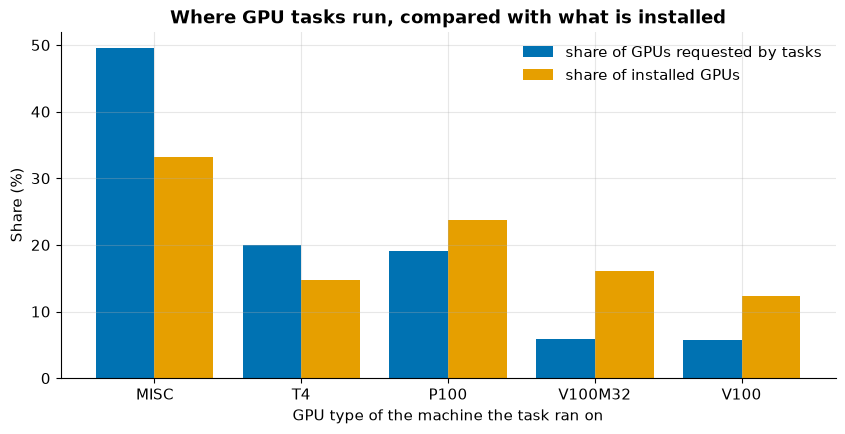

In [7]:
def gpu_type_spec_share(job, tags):
    """Share of jobs that name a GPU type, and the types they name."""
    j = job[["job_name", "inst_id"]].astype(str).merge(tags[["inst_id", "gpu_type_spec"]].astype({"inst_id": str}),
                                                      on="inst_id", how="left")
    named = j["gpu_type_spec"].notna()
    return named.mean(), j.loc[named, "gpu_type_spec"].astype(str).value_counts()


def gpu_share_by_type(task, supply):
    """Share of requested GPU-instances by the GPU type tasks ran on, next to the installed share."""
    t = task[task["plan_gpu"].notna() & task["gpu_type"].notna()].copy()
    t["gpu_demand"] = t["plan_gpu"] / 100 * t["inst_num"]
    d = t.groupby("gpu_type", observed=True)["gpu_demand"].sum()
    out = pd.DataFrame({"share_of_requested_gpus": d / d.sum(), "share_of_installed_gpus": supply["share_of_gpus"]})
    return out.fillna(0).sort_values("share_of_requested_gpus", ascending=False)


def plot_gpu_share_by_type(ax, shares):
    """Grouped bars: share of requested GPU-instances vs share of installed GPUs per type."""
    x = np.arange(len(shares))
    ax.bar(x - 0.2, shares["share_of_requested_gpus"] * 100, 0.4, label="share of GPUs requested by tasks", color=BLUE)
    ax.bar(x + 0.2, shares["share_of_installed_gpus"] * 100, 0.4, label="share of installed GPUs", color=ORANGE)
    ax.set_xticks(x, shares.index.astype(str))
    ax.set_title("Where GPU tasks run, compared with what is installed")
    ax.set_xlabel("GPU type of the machine the task ran on")
    ax.set_ylabel("Share (%)")
    ax.legend()


named_share, named_types = gpu_type_spec_share(job, tags)
print(f"jobs that name a GPU type in gpu_type_spec: {named_share:.1%}")
print(named_types.to_dict())
shares = gpu_share_by_type(task, supply)
display((shares * 100).round(1))
fig, ax = plt.subplots(figsize=(10, 4.5))
plot_gpu_share_by_type(ax, shares)
plt.show()

Takeaway: only 1.9% of jobs name a GPU type (mostly P100 or a V100 model), so the scheduler picks the type for
nearly everyone. Counted by requested GPUs and ignoring run time, MISC machines take half of the GPU tasks while holding
a third of the GPUs, and the two V100 types take 12% while holding 28%.

## 5. When work arrives

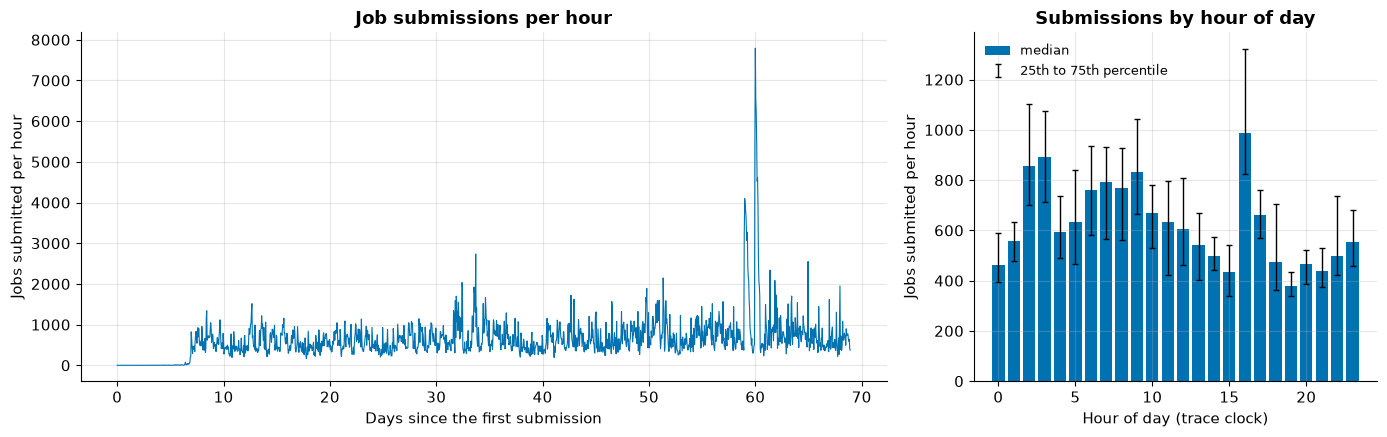

after day 7: median 596 jobs per hour, 99th percentile 3086, peak 7,793
hour of day with the highest median: 16 (988 jobs/h); lowest: 19 (380 jobs/h)


In [8]:
def arrivals_per_hour(job):
    """Number of job submissions in each hour of the trace."""
    h = np.floor(job["start_time"].dropna() / HOUR).astype("int64")
    counts = h.value_counts().sort_index()
    full = counts.reindex(np.arange(counts.index.min(), counts.index.max() + 1), fill_value=0)
    return full


def hour_of_day_profile(per_hour, ramp_days=RAMP_DAYS):
    """Median and interquartile range of hourly submissions by hour of day, after the ramp-up week."""
    after = per_hour[per_hour.index >= per_hour.index[0] + ramp_days * 24]
    g = pd.Series(after.values, index=after.index % 24).groupby(level=0)
    return pd.DataFrame({"q25": g.quantile(0.25), "median": g.median(), "q75": g.quantile(0.75)}), after


def plot_arrivals(axes, per_hour, hod):
    """Left: submissions per hour across the trace. Right: median submissions by hour of day."""
    days = (per_hour.index - per_hour.index[0]) * HOUR / DAY
    axes[0].plot(days, per_hour.values, color=BLUE, lw=0.8)
    axes[0].set_title("Job submissions per hour")
    axes[0].set_xlabel("Days since the first submission")
    axes[0].set_ylabel("Jobs submitted per hour")
    axes[1].bar(hod.index, hod["median"], color=BLUE, label="median")
    axes[1].errorbar(hod.index, hod["median"], yerr=[hod["median"] - hod["q25"], hod["q75"] - hod["median"]],
                     fmt="none", ecolor=BLACK, lw=1, capsize=2, label="25th to 75th percentile")
    axes[1].set_title("Submissions by hour of day")
    axes[1].set_xlabel("Hour of day (trace clock)")
    axes[1].set_ylabel("Jobs submitted per hour")
    axes[1].legend(loc="upper left", fontsize=9)


per_hour = arrivals_per_hour(job)
hod, after_ramp = hour_of_day_profile(per_hour)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [2, 1]})
plot_arrivals(axes, per_hour, hod)
plt.tight_layout()
plt.show()
print(f"after day {RAMP_DAYS}: median {after_ramp.median():.0f} jobs per hour, "
      f"99th percentile {after_ramp.quantile(0.99):.0f}, peak {after_ramp.max():,}")
print(f"hour of day with the highest median: {hod['median'].idxmax()} ({hod['median'].max():.0f} jobs/h); "
      f"lowest: {hod['median'].idxmin()} ({hod['median'].min():.0f} jobs/h)")

Takeaway: the first week is nearly empty while the trace ramps up. After that, a typical hour brings about 600
submissions, with a burst of 7,793 in one hour near day 60. By hour of day the median ranges from 380 jobs (hour 19)
to 988 (hour 16). Anything that splits the data by time should start after the ramp and expect bursts.

## 6. Heavy-tailed durations

A task's duration is `end_time - start_time` in `pai_task_table`. A complementary CDF (the share of tasks longer
than x) on log-log axes shows the tail: a line that stays high over several decades means a heavy tail, while an
exponential distribution with the same mean drops off quickly.

Only successful (Terminated) tasks are used. Failed tasks almost never record an end time in this trace (the next
cell counts them), so their durations cannot be measured.

failed tasks with an end time: 1,240 of 256,762 (0.5%)
Terminated tasks: median 10.7 min, 90th percentile 210 min, 99th percentile 1134 min, longest 7.2 days
longest 1% of tasks hold 25% of all task time; longest 10% hold 70%
share longer than 10x the mean: 0.0171 (an exponential would give 0.000045)


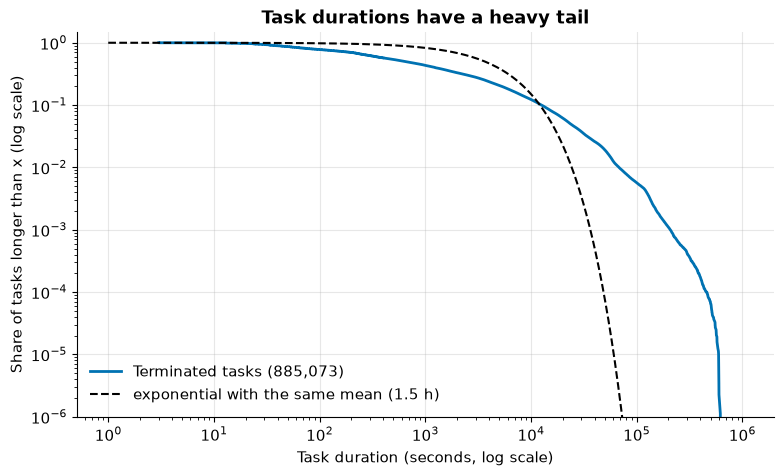

In [9]:
def task_durations(task):
    """Durations in seconds of finished tasks that have both timestamps, with their status."""
    t = task[task["status"].isin(LABELLED)].copy()
    t["duration"] = t["end_time"] - t["start_time"]
    return t[t["duration"].notna() & (t["duration"] >= 0)][["status", "duration", "task_name"]]


def ccdf(values):
    """Sorted values and the share of values strictly greater than each one."""
    v = np.sort(np.asarray(values, dtype=float))
    return v, 1.0 - np.arange(1, len(v) + 1) / len(v)


def plot_duration_ccdf(ax, durations):
    """CCDF of successful task duration, with an exponential of the same mean for comparison."""
    x, y = ccdf(np.clip(durations, 1, None))
    ax.loglog(x, y, color=BLUE, lw=2, label=f"Terminated tasks ({len(x):,})")
    mean = durations.mean()
    xs = np.logspace(0, 6, 200)
    ax.loglog(xs, np.exp(-xs / mean), color=BLACK, ls="--", lw=1.5,
              label=f"exponential with the same mean ({mean / HOUR:.1f} h)")
    ax.set_ylim(1e-6, 1.5)
    ax.set_title("Task durations have a heavy tail")
    ax.set_xlabel("Task duration (seconds, log scale)")
    ax.set_ylabel("Share of tasks longer than x (log scale)")
    ax.legend(loc="lower left")


dur = task_durations(task)
n_failed = int((task["status"] == "Failed").sum())
n_failed_dur = int((dur["status"] == "Failed").sum())
print(f"failed tasks with an end time: {n_failed_dur:,} of {n_failed:,} ({n_failed_dur / n_failed:.1%})")
term = dur.loc[dur["status"] == "Terminated", "duration"].to_numpy()
pct = np.percentile(term, [50, 90, 99]) / 60
print(f"Terminated tasks: median {pct[0]:.1f} min, 90th percentile {pct[1]:.0f} min, "
      f"99th percentile {pct[2]:.0f} min, longest {term.max() / DAY:.1f} days")
desc = np.sort(term)[::-1]
top1 = desc[: len(desc) // 100].sum() / desc.sum()
top10 = desc[: len(desc) // 10].sum() / desc.sum()
print(f"longest 1% of tasks hold {top1:.0%} of all task time; longest 10% hold {top10:.0%}")
print(f"share longer than 10x the mean: {(term > 10 * term.mean()).mean():.4f} "
      f"(an exponential would give {np.exp(-10):.6f})")
fig, ax = plt.subplots(figsize=(9, 5))
plot_duration_ccdf(ax, term)
plt.show()

Takeaway: the median successful task runs about 11 minutes, yet the longest 10% of tasks hold 70% of all task time,
and tasks longer than ten times the mean are about 380 times more common than an exponential model predicts
(1.7% against 0.0045%).

## 7. Queueing delay

A task launches at its job's submission time (in this trace `pai_task_table.start_time` equals the job's
`start_time` for every job), so the wait for resources shows up at the instance level. Here the queueing delay of a
task is the time from submission to its first instance starting, grouped by the GPU type of the machine it got.

tasks with a started instance: 1,165,642 of 1,261,050
all tasks: median delay 8 s, 90th percentile 110 s


,tasks,median (s),p90 (s),p99 (s),share > 10 min
gpu_type,,,,,
T4,219793,3.0,10.0,5392.0,0.042
no GPU,165866,3.0,4.0,1696.0,0.024
MISC,672554,10.0,102.0,3373.0,0.037
P100,66404,12.0,812.0,7997.0,0.112
V100,25392,96.0,6187.0,65835.0,0.217
V100M32,15632,104.0,3750.0,61100.0,0.170


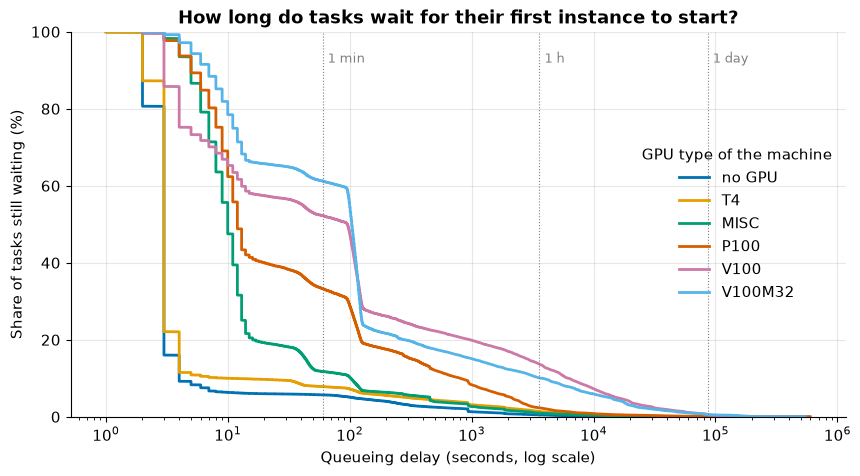

In [10]:
def task_queueing_delay(task, inst):
    """Seconds from task launch (job submission) to the first instance start, per task."""
    first = (inst.dropna(subset=["start_time"]).groupby(["job_name", "task_name"], observed=True)["start_time"]
             .min().rename("first_inst_start").reset_index())
    first["job_name"] = first["job_name"].astype(str)
    first["task_name"] = first["task_name"].astype(str)
    t = task[["job_name", "task_name", "start_time", "gpu_type", "plan_gpu", "inst_num"]].copy()
    t["job_name"] = t["job_name"].astype(str)
    t["task_name"] = t["task_name"].astype(str)
    t = t.merge(first, on=["job_name", "task_name"], how="inner")
    t["delay"] = t["first_inst_start"] - t["start_time"]
    t["gpu_type"] = t["gpu_type"].astype(str)
    t.loc[t["plan_gpu"].isna(), "gpu_type"] = "no GPU"
    return t[t["delay"] >= 0]


def delay_table(q):
    """Median, 90th and 99th percentile delay and share waiting over 10 minutes, per GPU type."""
    g = q.groupby("gpu_type")["delay"]
    out = pd.DataFrame({"tasks": g.size(), "median (s)": g.median(), "p90 (s)": g.quantile(0.9),
                        "p99 (s)": g.quantile(0.99), "share > 10 min": g.apply(lambda s: (s > 600).mean())})
    return out.sort_values("median (s)")


def plot_delay_ccdf(ax, q, order):
    """CCDF of queueing delay per GPU type."""
    colors = dict(zip(order, PALETTE))
    for gt in order:
        x, y = ccdf(q.loc[q["gpu_type"] == gt, "delay"].clip(lower=1))
        ax.semilogx(x, y * 100, color=colors[gt], lw=2, label=gt)
    for sec, lab in [(60, "1 min"), (3600, "1 h"), (86400, "1 day")]:
        ax.axvline(sec, color="grey", lw=0.8, ls=":")
        ax.text(sec * 1.1, 92, lab, color="grey", fontsize=9)
    ax.set_title("How long do tasks wait for their first instance to start?")
    ax.set_xlabel("Queueing delay (seconds, log scale)")
    ax.set_ylabel("Share of tasks still waiting (%)")
    ax.set_ylim(0, 100)
    ax.legend(title="GPU type of the machine")


q = task_queueing_delay(task, inst)
print(f"tasks with a started instance: {len(q):,} of {len(task):,}")
print(f"all tasks: median delay {q['delay'].median():.0f} s, 90th percentile {q['delay'].quantile(0.9):.0f} s")
dt = delay_table(q)
display(dt.round({"median (s)": 0, "p90 (s)": 0, "p99 (s)": 0, "share > 10 min": 3}))
order = [g for g in GPU_ORDER if g in dt.index]
fig, ax = plt.subplots(figsize=(10, 5))
plot_delay_ccdf(ax, q, order)
plt.show()

Takeaway: half of all tasks start within 8 seconds, but tasks placed on V100 or V100M32 machines wait about 100
seconds at the median and one to two hours at the 90th percentile, against 10 seconds at the 90th percentile on T4.
The drop near 100 seconds on the V100 and P100 curves looks like a scheduler retry interval. V100-class GPUs are the
scarce resource.

,tasks,median,p90
bucket,,,
<=0.5,424445,9.0,41.0
0.5-1,370840,10.0,183.0
1-2,43901,8.0,302.0
2-8,91892,7.0,123.0
8-32,59496,9.0,330.0
>32,9202,10.0,1447.0


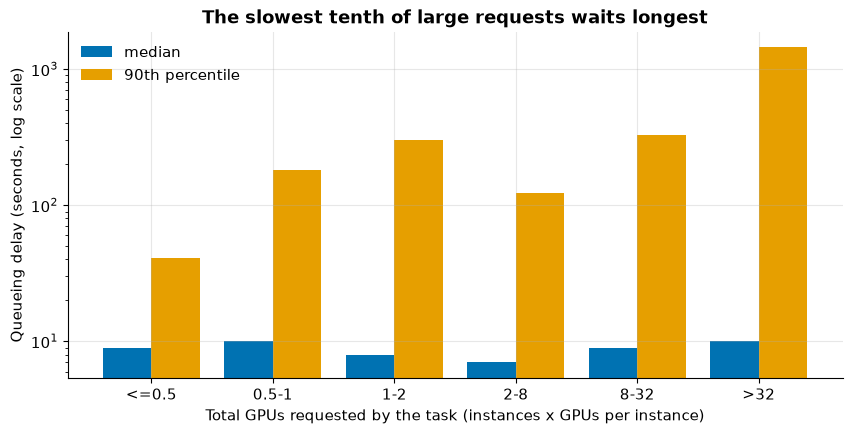

In [11]:
def delay_by_gpu_count(q):
    """Median and 90th percentile delay by total GPUs requested (instances x GPUs per instance)."""
    g = q[q["plan_gpu"].notna()].copy()
    g["total_gpus"] = g["plan_gpu"] / 100 * g["inst_num"]
    bins = [0, 0.5, 1, 2, 8, 32, np.inf]
    labels = ["<=0.5", "0.5-1", "1-2", "2-8", "8-32", ">32"]
    g["bucket"] = pd.cut(g["total_gpus"], bins=bins, labels=labels, include_lowest=True)
    out = g.groupby("bucket", observed=True)["delay"].agg(tasks="size", median="median", p90=lambda s: s.quantile(0.9))
    return out


def plot_delay_by_gpu_count(ax, table):
    """Bars of median and 90th percentile delay per total-GPU bucket, log y-axis."""
    x = np.arange(len(table))
    ax.bar(x - 0.2, table["median"].clip(lower=1), 0.4, color=BLUE, label="median")
    ax.bar(x + 0.2, table["p90"].clip(lower=1), 0.4, color=ORANGE, label="90th percentile")
    ax.set_yscale("log")
    ax.set_xticks(x, table.index.astype(str))
    ax.set_title("The slowest tenth of large requests waits longest")
    ax.set_xlabel("Total GPUs requested by the task (instances x GPUs per instance)")
    ax.set_ylabel("Queueing delay (seconds, log scale)")
    ax.legend()


by_count = delay_by_gpu_count(q)
display(by_count.round(0))
fig, ax = plt.subplots(figsize=(10, 4.5))
plot_delay_by_gpu_count(ax, by_count)
plt.show()

Takeaway: the median barely moves with request size (7 to 10 seconds), but the 90th percentile rises from 41 seconds
for tasks that need at most half a GPU to about 24 minutes for tasks that need more than 32 GPUs in total. The 2 to
8 GPU bucket breaks the trend, so size is not the whole story.

## 8. Failure rates at a glance

Among finished tasks (Failed or Terminated), how often does each kind fail? This is the label that parts 3 to 5 of
the series try to predict.

finished tasks: 1,141,835; failure rate 22.5%


,tasks,failure_rate
task_name,,
ReduceTask,3896,0.000
TVMTuneMain,1158,0.000
evaluator,14430,0.013
JupyterTask,1448,0.021
xComputeWorker,27264,0.022
ps,136848,0.023
TensorboardTask,8193,0.036
DecoderWorker,4070,0.043
worker,241503,0.119


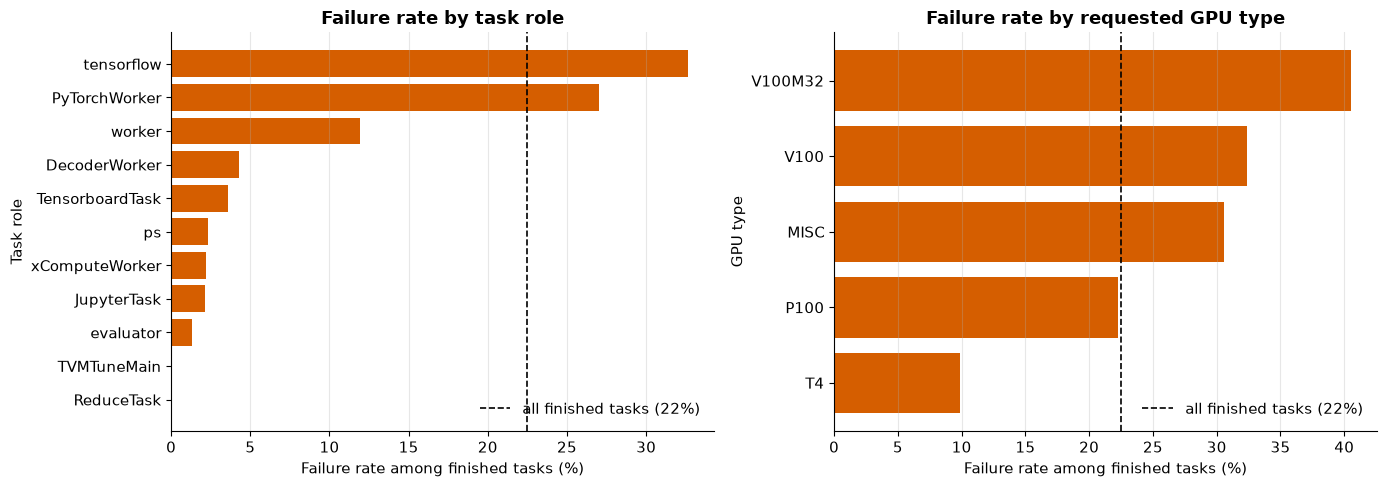

In [12]:
def failure_rate_by(task, col, min_tasks=1000):
    """Failure rate among finished tasks per value of ``col`` (values with at least ``min_tasks`` tasks)."""
    t = task[task["status"].isin(LABELLED)].copy()
    t[col] = t[col].astype(str).replace({"nan": "unspecified", "None": "unspecified"})
    t["failed"] = (t["status"] == "Failed").astype(int)
    g = t.groupby(col)["failed"].agg(tasks="size", failure_rate="mean")
    return g[g["tasks"] >= min_tasks].sort_values("failure_rate")


def plot_failure_rates(ax, table, title, ylabel, overall):
    """Horizontal bars of failure rate with the overall rate as a reference line."""
    ax.barh(table.index, table["failure_rate"] * 100, color=VERMILLION)
    ax.axvline(overall * 100, color=BLACK, ls="--", lw=1.2, label=f"all finished tasks ({overall:.0%})")
    ax.set_title(title)
    ax.set_xlabel("Failure rate among finished tasks (%)")
    ax.set_ylabel(ylabel)
    ax.legend(loc="lower right")
    ax.grid(axis="y", visible=False)


fin = task[task["status"].isin(LABELLED)]
overall = (fin["status"] == "Failed").mean()
print(f"finished tasks: {len(fin):,}; failure rate {overall:.1%}")
by_role = failure_rate_by(task, "task_name")
by_type = failure_rate_by(task, "gpu_type")
display(by_role.round(3))
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot_failure_rates(axes[0], by_role, "Failure rate by task role", "Task role", overall)
plot_failure_rates(axes[1], by_type, "Failure rate by requested GPU type", "GPU type", overall)
plt.tight_layout()
plt.show()

Takeaway: 22.5% of finished tasks fail, and the rate swings widely by role: about 1% for evaluators, 2% for
parameter servers, 12% for distributed workers and 33% for plain `tensorflow` tasks. Part 3 asks how much of that a
model can predict before a task runs.

In [13]:
save_cover(lambda ax: plot_delay_ccdf(ax, q, order))
print("saved cover.png (queueing delay by GPU type)")

saved cover.png (queueing delay by GPU type)


## 9. What we found

- The cluster has 6,742 GPUs on 1,897 machines; a third are older MISC cards, and every P100 and T4 machine has
  2 GPUs.
- Work is concentrated: one of 1,433 users submits 27% of the 1,055,501 jobs, and the top 10 submit 54%.
- 54% of GPU tasks ask for a fraction of a GPU, with a quarter GPU the second most common request, and only 1.9%
  of jobs name a GPU type.
- Task durations are heavy-tailed: the median successful task runs about 11 minutes while the longest 10% hold 70%
  of the total task time.
- Queueing is short for most tasks (median 8 seconds) and long on V100-class machines, where the 90th percentile
  wait is one to two hours.

### Limitations

- Times are shifted, so hour of day is in trace time and calendar effects (weekends, holidays) cannot be named.
- The first two weeks of the trace are sparse, which pulls down any average that includes them.
- Delay here is submission to first instance start; for multi-instance tasks the last instance may start later.
- Only 0.5% of failed tasks record an end time, so durations describe successful tasks only.
- `gpu_type` in the task table is the GPU a task ran on; the delay by GPU type mixes jobs that asked for that type
  with jobs the scheduler placed there.

### Ideas to try

- Split queueing delay by user, or by whether the job named a GPU type, to see what drives the long waits.
- Fit a log-normal or Pareto tail to the durations and compare with the CCDF above.
- Use `pai_group_tag_table` to compare repeated jobs (same group tag) with one-off jobs.

### The series

1. Alibaba PAI GPU trace 2020: a complete EDA (this notebook)
2. [Where cluster GPUs sit idle: utilization, over-requesting and fragmentation](https://www.kaggle.com/code/swapnilshukla007/where-cluster-gpus-sit-idle)
3. [Predicting GPU task failure: a LightGBM baseline explained with SHAP](https://www.kaggle.com/code/swapnilshukla007/predicting-gpu-task-failure-lightgbm-and-shap)
4. [Kolmogorov-Arnold additive models from scratch: B-spline edge functions in PyTorch](https://www.kaggle.com/code/swapnilshukla007/kolmogorov-arnold-additive-models-from-scratch)
5. [Reading the splines: KAAM shape functions vs SHAP on the same tasks](https://www.kaggle.com/code/swapnilshukla007/reading-the-splines-kaam-curves-vs-shap)

If something here is wrong or unclear, a comment helps more than anything; an upvote helps others find it.